# Assignment 4: N-gram Language Models and Smoothing

This notebook trains simple word-level language models using the local files:
`train.csv`, `val.csv`, and `test.csv`.

We compare five methods:
1. Unsmoothed maximum-likelihood estimation
2. Laplace (add-one) smoothing
3. Add-k smoothing
4. Interpolation
5. Kneser-Ney smoothing

The goal is to compare the models using **perplexity**. Lower perplexity means better predictions.

## 1. Concepts 

- An **n-gram** is a sequence of `n` words. A unigram uses one word, a bigram uses two, a trigram uses three, and a quadgram uses four.
- A language model estimates the probability of the next word from the previous words.
- **Smoothing** gives a small probability to word combinations that were not seen in training.
- **Perplexity** measures how surprised the model is. Smaller is better. A zero probability causes infinite perplexity.
- `<s>` marks the start of a sentence, `</s>` marks the end, and `<UNK>` represents rare or unknown words.

The validation set is used for choosing parameters. The test set is used only for the final comparison.

In [7]:
# 2. Import libraries and set simple options

import math
import random
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import pandas as pd

random.seed(42)

# Use None to use all local training rows. A smaller number is useful for a quick test.
MAX_TRAIN_ROWS = None
MIN_WORD_FREQUENCY = 2
ORDERS = [1, 2, 3, 4]
ADD_K = 0.1
KN_DISCOUNT = 0.75

print("Ready. Local data will be used; no download is needed.")

Ready. Local data will be used; no download is needed.


In [2]:
# Read the three local CSV files

def read_text_file(path):
    data = pd.read_csv(path, usecols=["text"])
    data["text"] = data["text"].fillna("").astype(str)
    return data["text"].tolist()

train_sentences = read_text_file("train.csv")
dev_sentences = read_text_file("val.csv")
test_sentences = read_text_file("test.csv")

if MAX_TRAIN_ROWS is not None:
    train_sentences = train_sentences[:MAX_TRAIN_ROWS]

print(f"Training sentences:   {len(train_sentences):,}")
print(f"Validation sentences: {len(dev_sentences):,}")
print(f"Test sentences:       {len(test_sentences):,}")
print("Example:", train_sentences[0][:120])

Training sentences:   18,400
Validation sentences: 2,300
Test sentences:       2,300
Example: प्रकृतेः परतो नित्यमिन्द्रियैरप्यगोचरः । 012a


## 3. Load the local data

Each CSV row contains one text sample and a language label. For this assignment we need only the text. The label is ignored because this is a language-model experiment, not a classification experiment.

The existing train, validation, and test files are already separate, so we do not download or re-split a corpus.

In [3]:
# 4. Tokenize words and replace rare words with <UNK>

def tokenize(text):
    return text.split()

train_tokens_raw = [tokenize(text) for text in train_sentences]
dev_tokens_raw = [tokenize(text) for text in dev_sentences]
test_tokens_raw = [tokenize(text) for text in test_sentences]

word_frequency = Counter(word for sentence in train_tokens_raw for word in sentence)
vocabulary = {word for word, count in word_frequency.items() if count >= MIN_WORD_FREQUENCY}
vocabulary.update({"<UNK>", "</s>"})


def replace_unknown_words(sentences):
    return [
        [word if word in vocabulary else "<UNK>" for word in sentence]
        for sentence in sentences
    ]


train_tokens = replace_unknown_words(train_tokens_raw)
dev_tokens = replace_unknown_words(dev_tokens_raw)
test_tokens = replace_unknown_words(test_tokens_raw)
VOCAB_SIZE = len(vocabulary)

print(f"Vocabulary size: {VOCAB_SIZE:,}")
print("Rare and unseen words are represented by <UNK>.")

Vocabulary size: 32,988
Rare and unseen words are represented by <UNK>.


In [4]:
# Count unigrams, bigrams, trigrams, and quadgrams

def build_counts(sentences, order):
    ngram_counts = Counter()
    context_counts = Counter()

    for words in sentences:
        padded = ["<s>"] * (order - 1) + words + ["</s>"]
        for index in range(order - 1, len(padded)):
            context = tuple(padded[index - order + 1:index])
            word = padded[index]
            ngram_counts[context + (word,)] += 1
            context_counts[context] += 1

    return ngram_counts, context_counts


NGRAM_COUNTS = {}
CONTEXT_COUNTS = {}
for order in ORDERS:
    NGRAM_COUNTS[order], CONTEXT_COUNTS[order] = build_counts(train_tokens, order)
    print(f"{order}-gram types: {len(NGRAM_COUNTS[order]):,}")

1-gram types: 32,988
2-gram types: 159,626
3-gram types: 242,443
4-gram types: 277,404


## 6. Probability models

The unsmoothed model uses the observed count directly. The other models give some probability to unseen n-grams:

- **Laplace:** add 1 to every count.
- **Add-k:** add a smaller value, here `k = 0.1`.
- **Interpolation:** combine the current order with the lower order.
- **Kneser-Ney:** discount counts and use continuation probability at the unigram level.

Finally, one common perplexity function evaluates all models.

In [5]:
# Probability functions and perplexity

def mle_probability(word, context):
    order = len(context) + 1
    numerator = NGRAM_COUNTS[order].get(context + (word,), 0)
    denominator = CONTEXT_COUNTS[order].get(context, 0)
    return numerator / denominator if denominator else 0.0


def laplace_probability(word, context):
    order = len(context) + 1
    numerator = NGRAM_COUNTS[order].get(context + (word,), 0) + 1
    denominator = CONTEXT_COUNTS[order].get(context, 0) + VOCAB_SIZE
    return numerator / denominator


def add_k_probability(word, context, k=ADD_K):
    order = len(context) + 1
    numerator = NGRAM_COUNTS[order].get(context + (word,), 0) + k
    denominator = CONTEXT_COUNTS[order].get(context, 0) + k * VOCAB_SIZE
    return numerator / denominator


# Continuation probability for Kneser-Ney
preceding_words = defaultdict(set)
for bigram in NGRAM_COUNTS[2]:
    preceding_words[bigram[1]].add(bigram[0])

total_bigram_types = len(NGRAM_COUNTS[2])

def continuation_probability(word):
    return len(preceding_words.get(word, set())) / total_bigram_types


followers = {}
for order in [2, 3, 4]:
    followers[order] = defaultdict(set)
    for ngram in NGRAM_COUNTS[order]:
        followers[order][ngram[:-1]].add(ngram[-1])


def kneser_ney_probability(word, context):
    order = len(context) + 1
    if order == 1:
        return max(continuation_probability(word), 1e-12)

    context_count = CONTEXT_COUNTS[order].get(context, 0)
    if context_count == 0:
        return kneser_ney_probability(word, context[1:])

    count = NGRAM_COUNTS[order].get(context + (word,), 0)
    discounted_count = max(count - KN_DISCOUNT, 0) / context_count
    backoff_weight = KN_DISCOUNT * len(followers[order][context]) / context_count
    return discounted_count + backoff_weight * kneser_ney_probability(word, context[1:])


def interpolated_probability(word, context, lambdas):
    order = len(context) + 1
    if order == 1:
        return lambdas[1] * mle_probability(word, ()) + (1 - lambdas[1]) / VOCAB_SIZE

    higher_order = mle_probability(word, context)
    lower_order = interpolated_probability(word, context[1:], lambdas)
    return lambdas[order] * higher_order + (1 - lambdas[order]) * lower_order


def perplexity(sentences, probability_function, order):
    log_probability = 0.0
    number_of_words = 0

    for words in sentences:
        padded = ["<s>"] * (order - 1) + words + ["</s>"]
        for index in range(order - 1, len(padded)):
            context = tuple(padded[index - order + 1:index])
            probability = probability_function(padded[index], context)
            if probability <= 0:
                return math.inf
            log_probability += math.log(probability)
            number_of_words += 1

    return math.exp(-log_probability / number_of_words)


# Interpolation uses one simple lambda for every order.
lambdas = {order: 0.7 for order in ORDERS}

models = {
    "Unsmoothed": mle_probability,
    "Laplace": laplace_probability,
    "Add-k": add_k_probability,
    "Interpolated": lambda word, context: interpolated_probability(word, context, lambdas),
    "Kneser-Ney": kneser_ney_probability,
}

results = []
for order in ORDERS:
    for name, probability_function in models.items():
        results.append({
            "N-gram": order,
            "Model": name,
            "Validation PPL": perplexity(dev_tokens, probability_function, order),
            "Test PPL": perplexity(test_tokens, probability_function, order),
        })

results_df = pd.DataFrame(results)
results_df

,N-gram,Model,Validation PPL,Test PPL
0,1,Unsmoothed,3.900863e+02,3.904223e+02
1,1,Laplace,4.047523e+02,4.051682e+02
2,1,Add-k,3.914124e+02,3.917556e+02
3,1,Interpolated,4.614234e+02,4.621553e+02
4,1,Kneser-Ney,5.588115e+02,5.596321e+02
5,2,Unsmoothed,inf,inf
6,2,Laplace,1.687475e+03,1.705202e+03
7,2,Add-k,7.885650e+02,7.934218e+02
8,2,Interpolated,1.725500e+02,1.703967e+02
9,2,Kneser-Ney,1.478416e+02,1.469470e+02


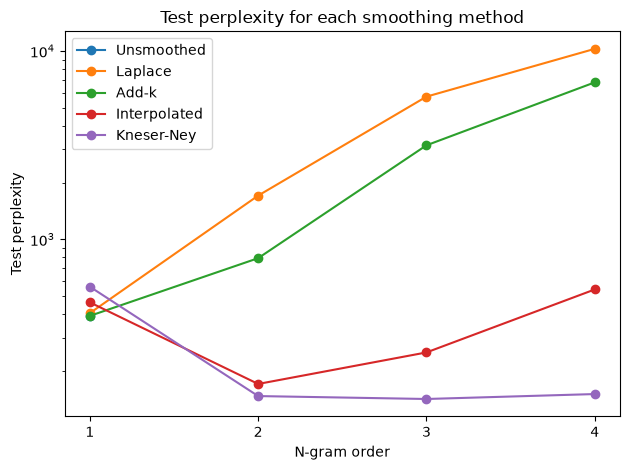

In [6]:
# Plot test perplexity

for model_name in models:
    model_rows = results_df[results_df["Model"] == model_name]
    finite_rows = model_rows.replace([math.inf, -math.inf], float("nan")).dropna()
    plt.plot(finite_rows["N-gram"], finite_rows["Test PPL"], marker="o", label=model_name)

plt.xlabel("N-gram order")
plt.ylabel("Test perplexity")
plt.title("Test perplexity for each smoothing method")
plt.xticks(ORDERS)
plt.yscale("log")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Compare the models

Read the result table row by row. For the same n-gram order, the model with the smaller test perplexity performs better.

The final graph shows how test perplexity changes as the model uses more context.